# 07 Fault Detection and PMI

**Scientific question.** Which residuals preserve one-turn modulation?

**Learning objectives.** Derive the diagnostic pipeline and interpret provisional record groups.

**Prerequisites.** Install the project requirements. Configure the data directory for raw-record checks. Portable evidence review also uses the existing run artifacts.

**Dataset and run.** Course gearbox at 3.2 kHz, the project’s designated training and held-out development records, and the explicit diagnostic or blind availability files where relevant.

**Execution.** This clean-kernel replay reads the evidence cited in each code cell. Use the explicit project pipeline for full fitting and the notebook build script for review replay. The companion guide contains notation, figures, and worked examples.

In [1]:
import hashlib
import json
import os
from pathlib import Path
import platform
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
get_ipython().run_line_magic("matplotlib", "inline")
from IPython.display import Image, display

hint = os.environ.get("SRC_PROJECT_DIR")
locations = [Path(hint).resolve()] if hint else [Path.cwd(), *Path.cwd().parents]
ROOT = next((p for p in locations if (p / "src" / "src_gearbox").is_dir()), None)
if ROOT is None:
    raise RuntimeError("Open within the project or set SRC_PROJECT_DIR.")
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))
DATA = Path(os.environ.get("SRC_DATA_DIR", ROOT / "data" / "raw"))
RESULTS = ROOT / "results"
START = 1792
N = 24000
pd.options.display.max_colwidth = 120
pd.options.display.width = 115
plt.rcParams.update({"figure.dpi": 105, "axes.grid": True, "grid.alpha": .18})

def table(relative):
    file = ROOT / relative
    if not file.is_file():
        print(f"NOT AVAILABLE YET · {relative}")
        return None
    return pd.read_csv(file)

def evidence(relative):
    file = ROOT / relative
    if not file.is_file():
        print(f"NOT AVAILABLE YET · {relative}")
        return {}
    return json.loads(file.read_text(encoding="utf-8"))

def show_fig(relative, width=780):
    file = ROOT / relative
    if file.is_file():
        display(Image(filename=str(file), width=width))
    else:
        print(f"NOT AVAILABLE YET · {relative}")

def forecast(relative):
    file = ROOT / relative
    if not file.is_file():
        print(f"NOT AVAILABLE YET · {relative}")
        return {}
    with np.load(file, allow_pickle=False) as source:
        arrays = {key: source[key] for key in source.files}
    np.testing.assert_array_equal(arrays["target_indices"], np.arange(START, N))
    assert np.isfinite(arrays["actual"]).all()
    return arrays

def align_forecasts(reference, *others):
    for other in others:
        for key in ("target_indices", "actual", "rpm", "time_s"):
            np.testing.assert_array_equal(reference[key], other[key])

def draw_forecast(bundle, keys, view=slice(5000, 5200)):
    if not bundle:
        return
    y, t = bundle["actual"], bundle["time_s"]
    fig, ax = plt.subplots(2, 1, figsize=(9.0, 4.0), sharex=True, layout="constrained")
    ax[0].plot(t[view], y[view], color="#141a26", lw=1.2, label="Measured")
    for key, label in keys.items():
        if key in bundle:
            pred = bundle[key]
            ax[0].plot(t[view], pred[view], lw=0.9, label=label)
            ax[1].plot(t[view], (y-pred)[view], lw=0.9, label=label)
    ax[0].legend(ncol=3, fontsize=8)
    ax[0].set_ylabel("Std. vibration")
    ax[1].set(ylabel="Std. residual", xlabel="Acquisition time (s)")
    plt.show()

print("Read-only evidence replay.", f"Python {platform.python_version()}",
      f"NumPy {np.__version__}. One-step observed history through t−1.")

Read-only evidence replay. Python 3.12.14 NumPy 2.5.5. One-step observed history through t−1.


### Offline angular diagnosis from causal forecast residuals

Form $e_t=x_t-\hat x_t$ on the common target range. Integrate measured
$n/60$ to turns and interpolate the residual to a uniform turn grid.
The Hilbert-envelope magnitude summarizes modulation. With centered
envelope $v_q$, define $R(\ell)=\sum_qv_qv_{q+\ell}$, and compute
$\mathrm{PMI}=R(\ell)/[R(0)-R(\ell)]$. On a grid of 2,048 samples per turn,
$\ell=2048$ matches one revolution. The historical index convention
evaluates lag 2047 under semantic comparison. These postrecord steps
may use the completed residual series.

In [2]:
from src_gearbox.diagnostics.pmi import pmi_from_envelope

phase = np.arange(8*64)/64
periodic = 2 + np.cos(2*np.pi*phase)
measured = pmi_from_envelope(periodic,64)
display(measured)
np.testing.assert_allclose(measured.correlation, 7/8, atol=1e-12)
np.testing.assert_allclose(measured.value, 7.0, atol=1e-12)
print("Analytical biased one-turn correlation = 7/8; PMI = 7")
parity = evidence("results/fault/matlab_conformance.json")
display(parity)

PMI(value=7.0, correlation=0.875, lag=64, status='ok')

Analytical biased one-turn correlation = 7/8; PMI = 7


{'reference_script': 'fdt_featcal.m',
 'reference_sha256': '6c1206b0cb7e1098b6b9b52cf437e2ba5097e05334e9c00cee51e5fc8fabbf06',
 'literal_branch_confirmed_in_reference': True,
 'exact_matlab_parity': 'unverified',
 'exact_parity_reason': 'original angular resampling helper and MATLAB numerical gold outputs not supplied',
 'course_mode': 'lecturer_compatible: analytic envelope of mean-centered signal, zero-lag energy denominator, lag S−1',
 'lag_corrected': 'lecturer envelope convention at exact lag S',
 'mathematically_specified': 'direct Hilbert magnitude then center envelope at exact lag S',
 'analysis_convention': 'offline; no padding, bandpass, prewhitening, or extra trimming beyond common warm-up',
 'known_fixture': {'rotations': 8,
  'shaft_rpm': 120,
  'sample_rate_hz': 3200,
  'points_per_revolution': 1600,
  'exact_lag_analytical_pmi': 7,
  'observed_lecturer': 7.009579585594343,
  'observed_corrected_lag': 7.000000000000215,
  'observed_mathematical': 7.000000000000204}}

,model,metric,n_A,n_B,median_A,median_B,median_gap_B_minus_A,median_gap_ci_low,median_gap_ci_high,margin_min_B_minus_max_A,central_margin_p05_B_minus_p95_A,conditional_auc_B_high,conditional_auc_ci_low,conditional_auc_ci_high,label_status
0,raw,lecturer_compatible,98,100,0.097142,0.088550,-0.008593,-0.015354,-0.002262,-0.118824,-0.082770,0.364286,0.286921,0.44288,provisional_index_group_only
1,sparse_lpv_arma,lecturer_compatible,98,100,0.040144,0.112696,0.072552,0.068445,0.076609,0.019399,0.037276,1.000000,1.000000,1.00000,provisional_index_group_only
2,archived_src_corrected,lecturer_compatible,98,100,0.028786,0.132133,0.103347,0.099509,0.106796,0.055907,0.069257,1.000000,1.000000,1.00000,provisional_index_group_only
3,primary_pi_src,lecturer_compatible,98,100,0.030189,0.114919,0.084730,0.081459,0.088689,0.035803,0.055495,1.000000,1.000000,1.00000,provisional_index_group_only
4,pi_src_adapter_off,lecturer_compatible,98,100,0.030998,0.115030,0.084032,0.080635,0.087788,0.036015,0.054571,1.000000,1.000000,1.00000,provisional_index_group_only
5,pi_src_fixed,lecturer_compatible,98,100,0.033697,0.125202,0.091505,0.087906,0.095025,0.045377,0.058176,1.000000,1.000000,1.00000,provisional_index_group_only


{'sigtest_present': False,
 'sigfault2_present': False,
 'blind_execution': 'blocked: sigtest and sigfault2 missing',
 'verified_condition_labels': False,
 'verified_calibration': False,
 'classification_metrics': 'unavailable; index-group AUC is conditional only',
 'pmi_standardization': 'withheld without separate verified healthy calibration'}

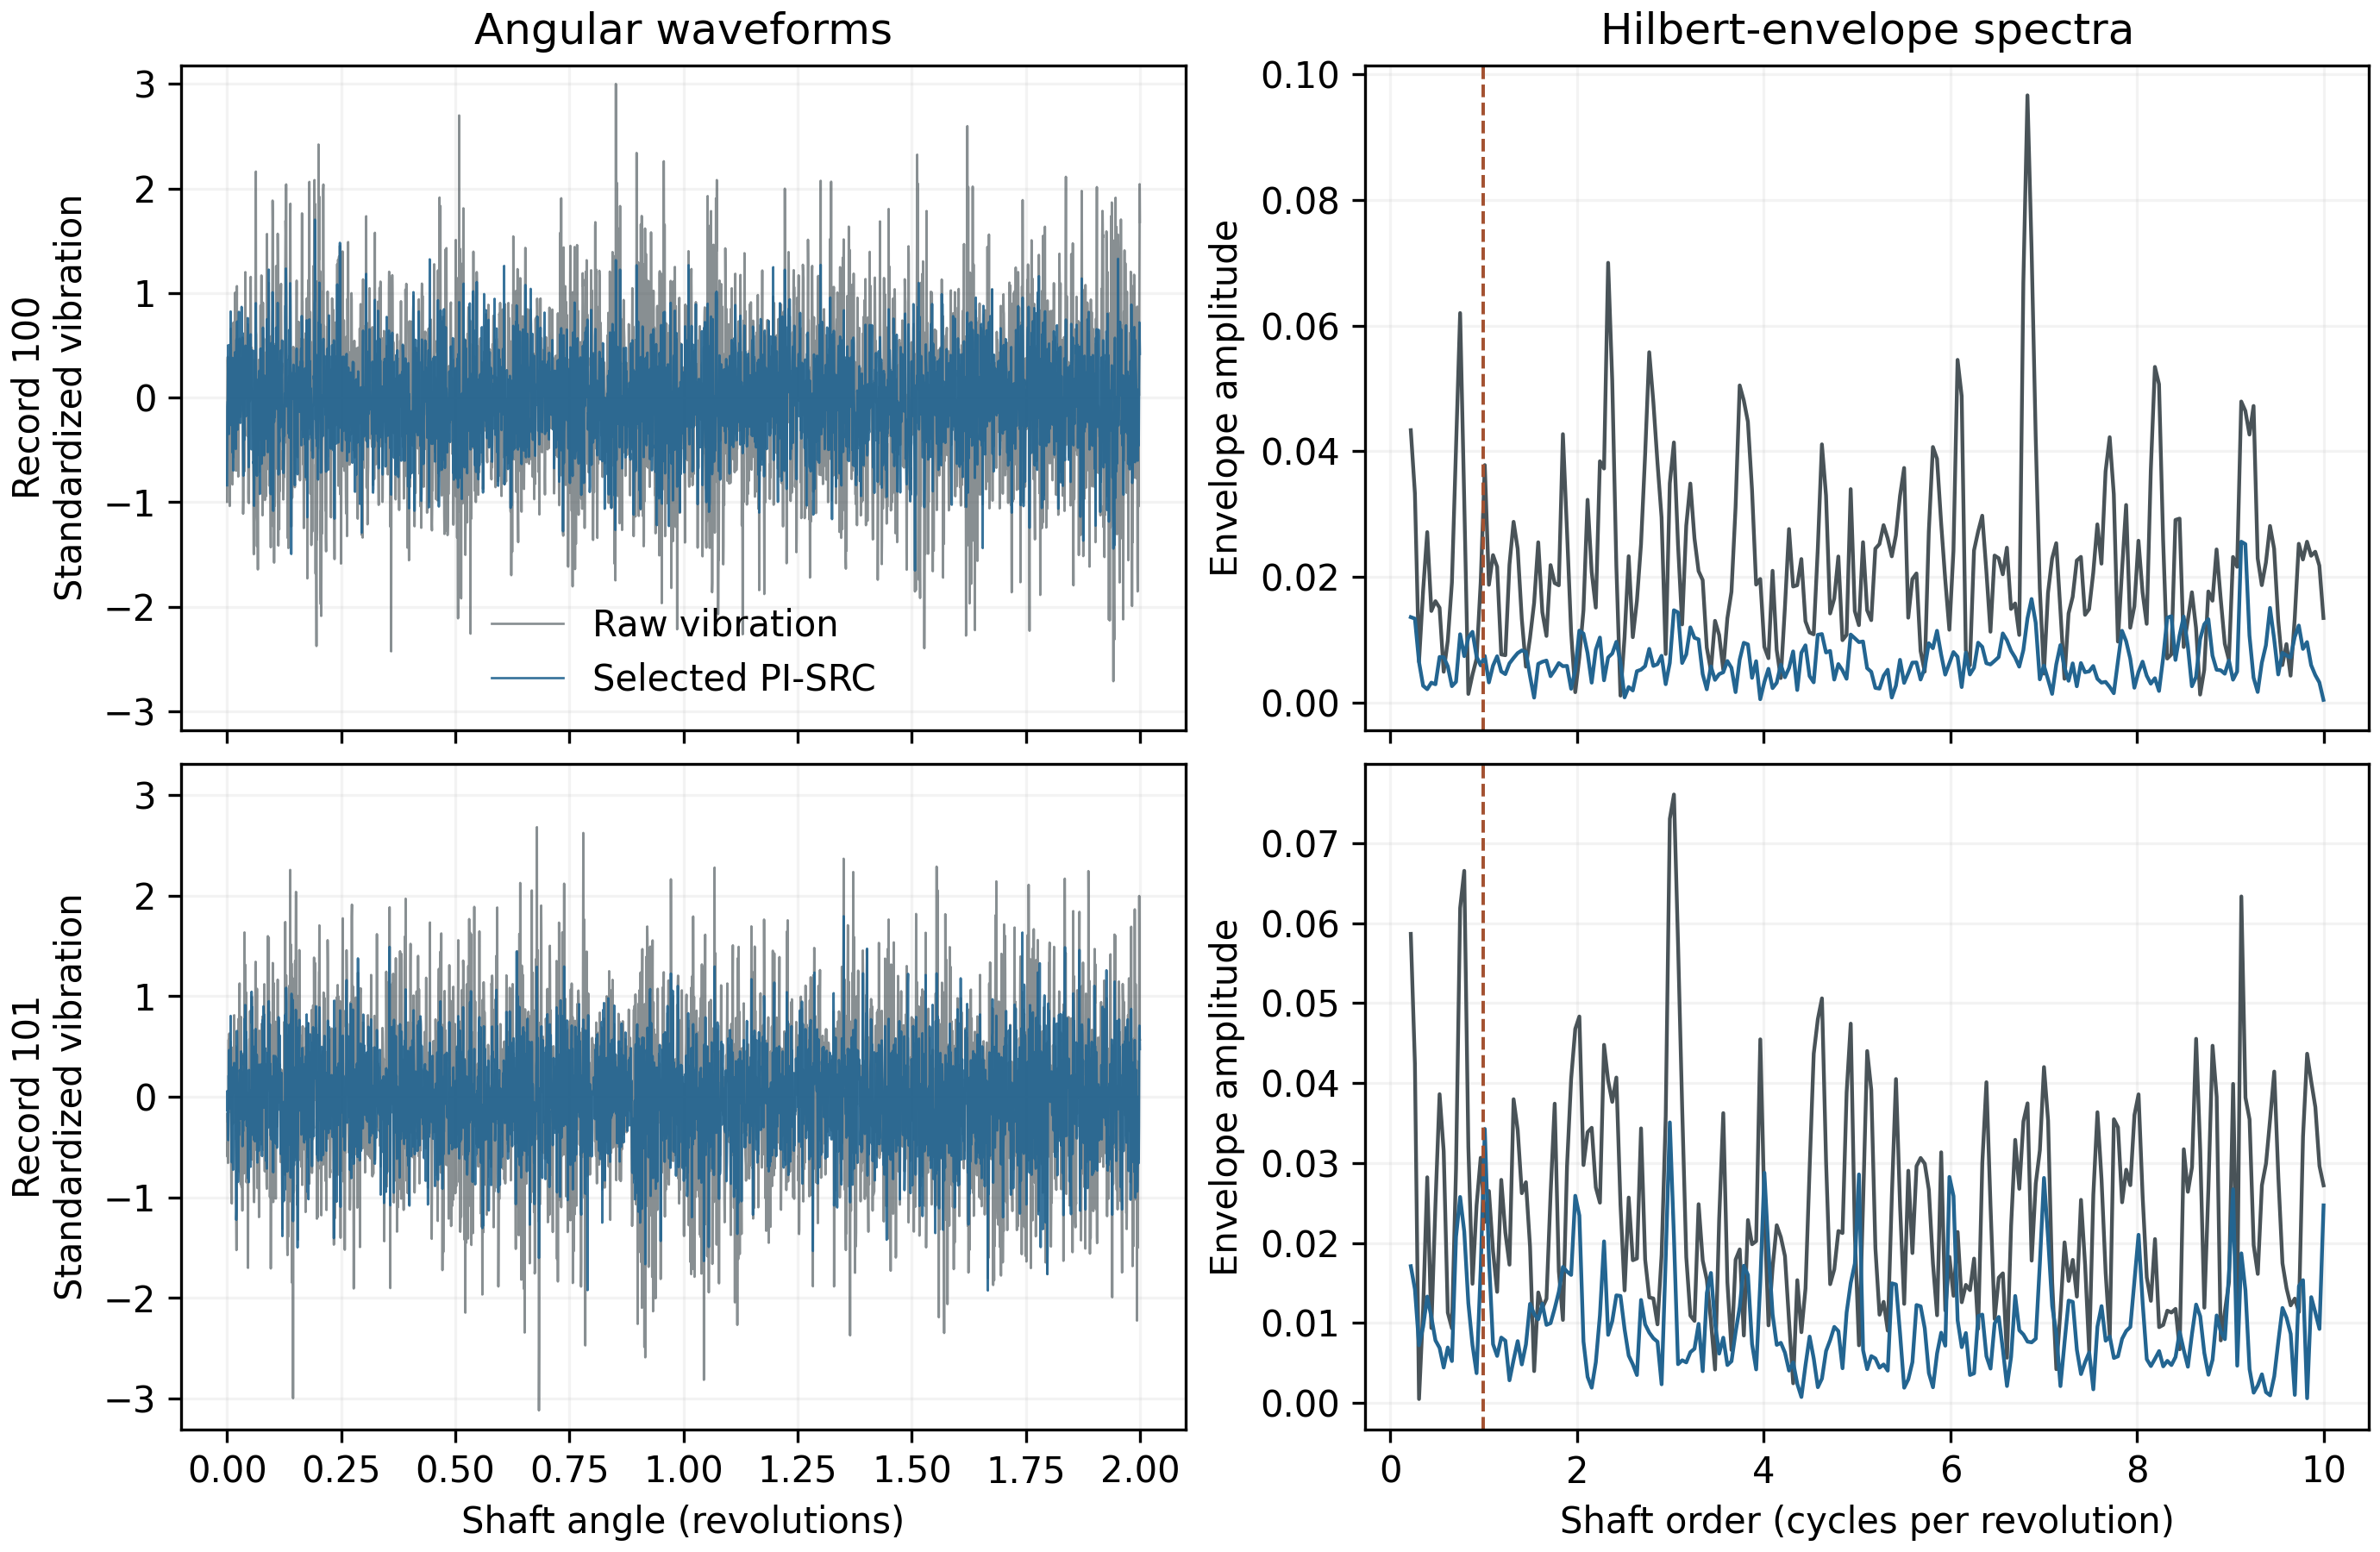

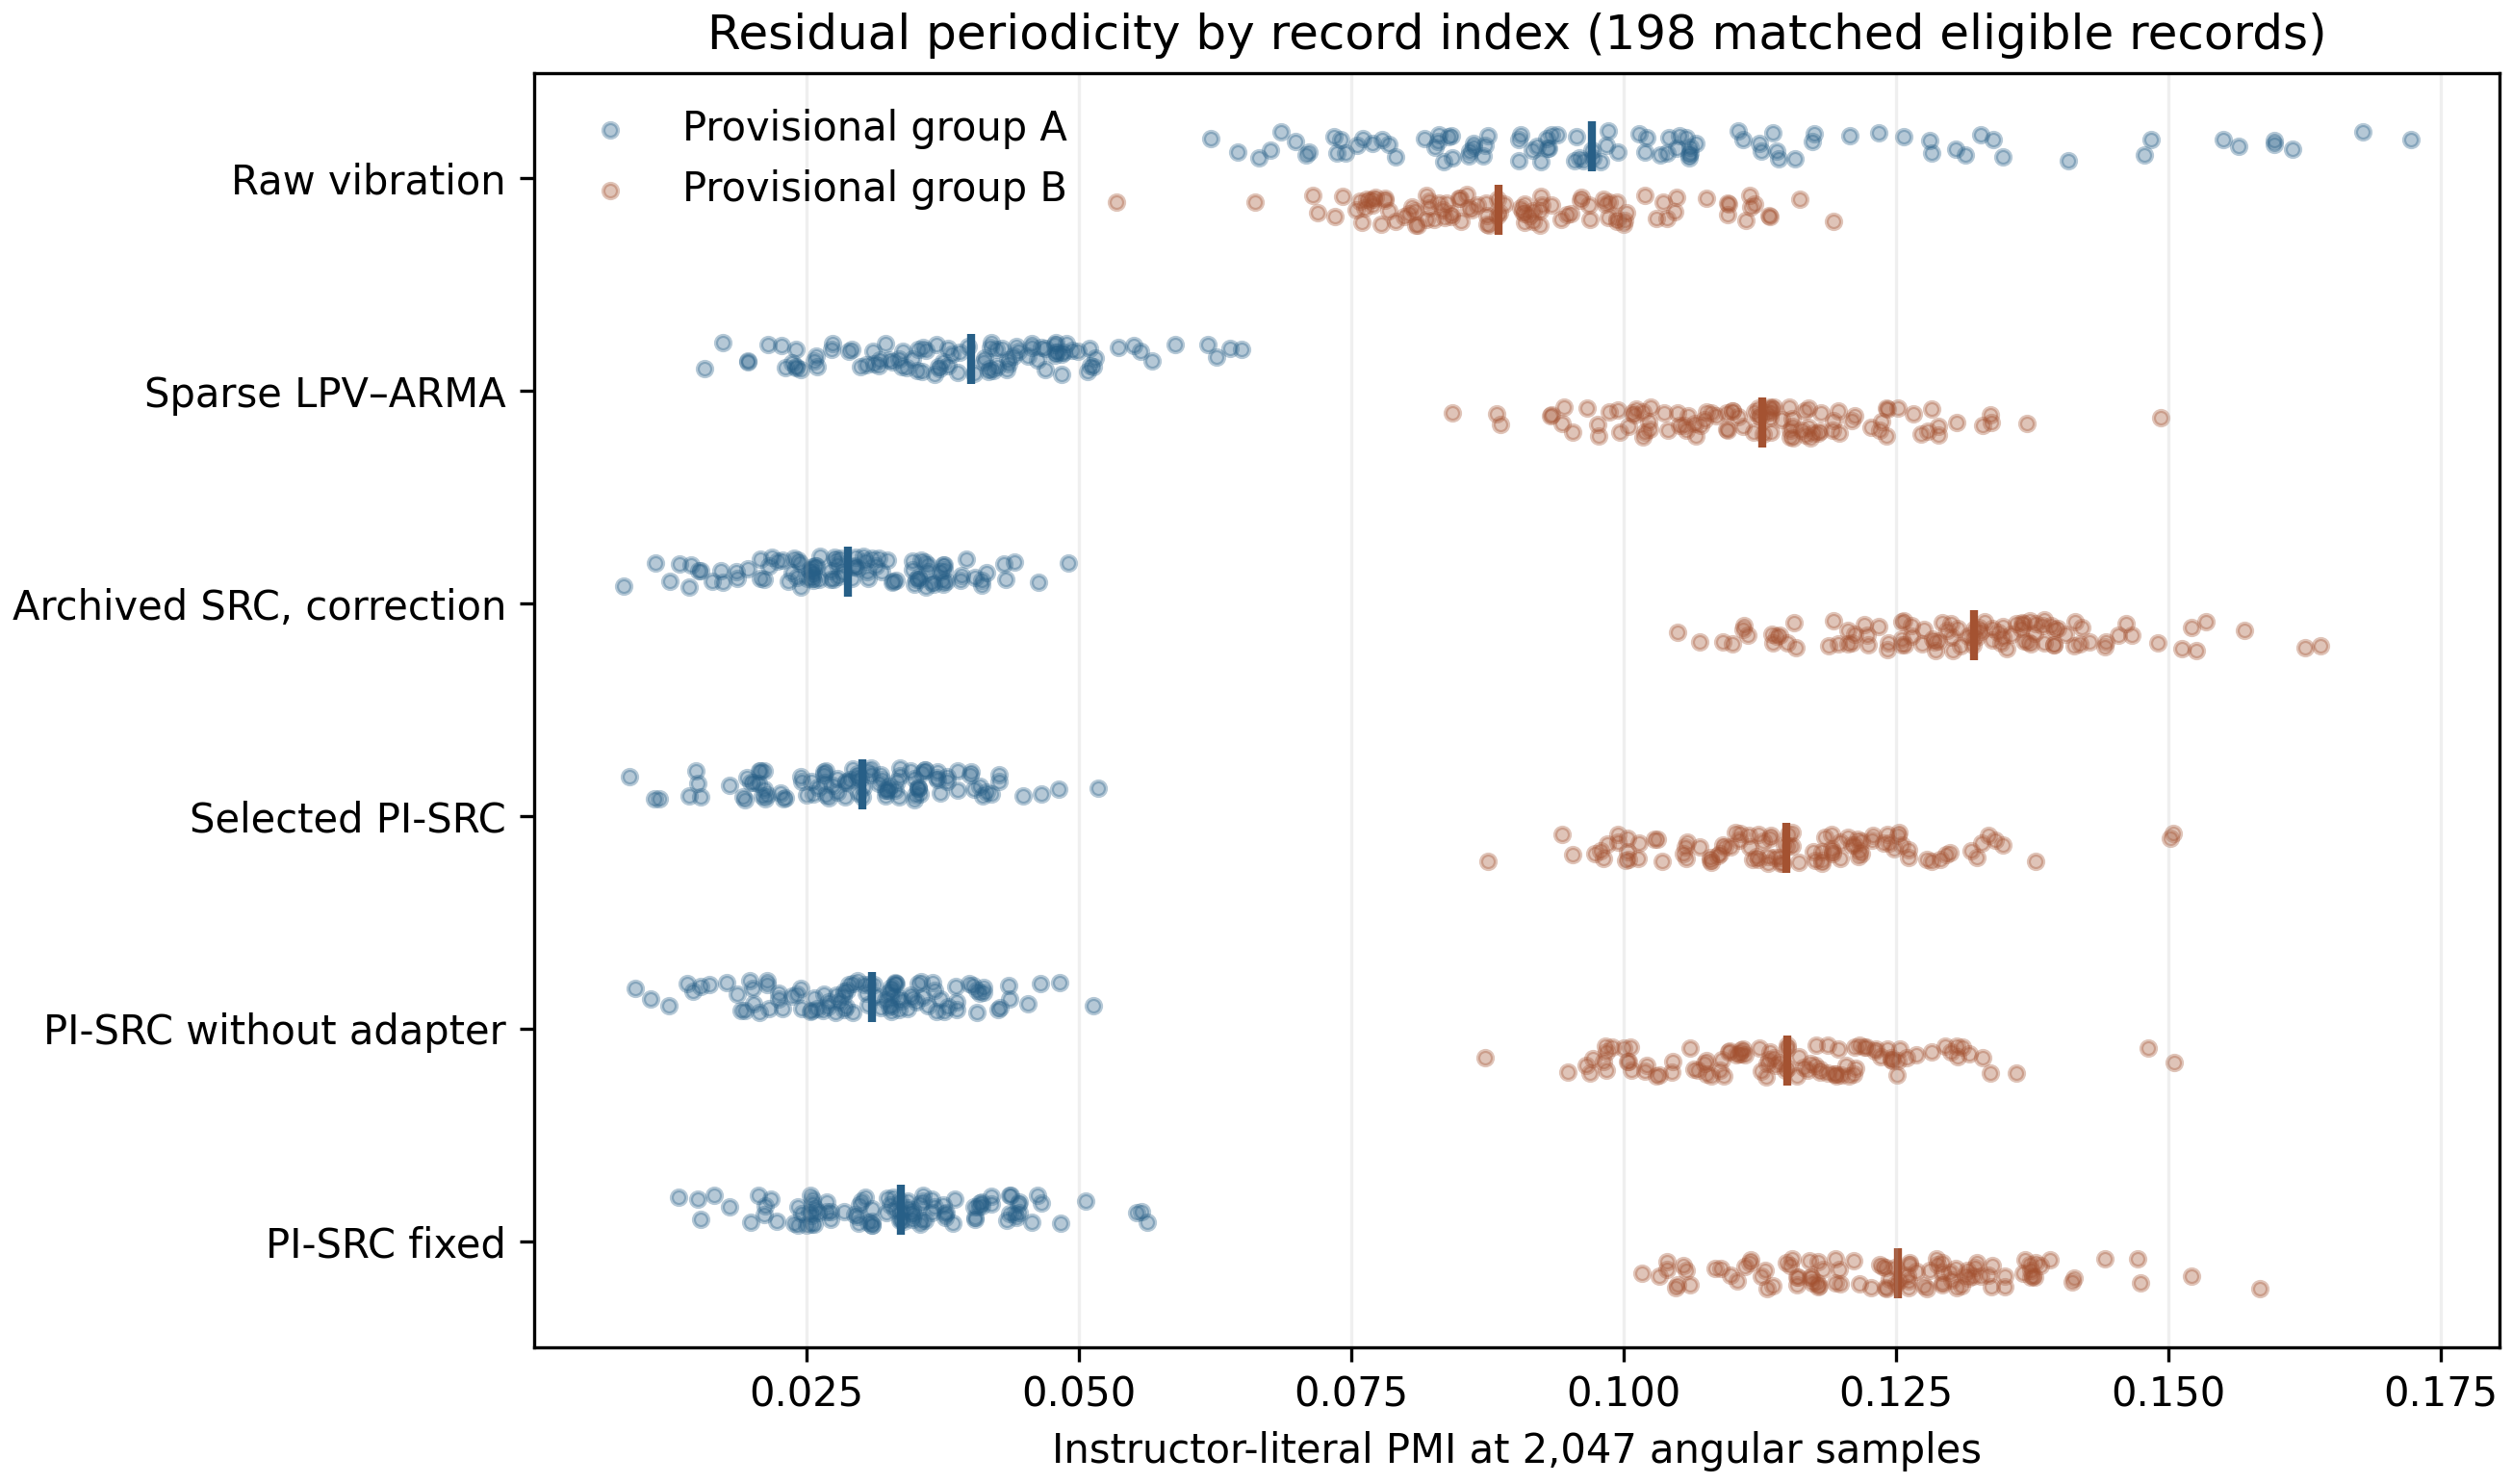

In [3]:
fault = table("results/fault/fault_group_summary.csv")
if fault is not None:
    display(fault.loc[fault.metric.eq("lecturer_compatible")])
integrity = evidence("results/fault/availability.json")
if integrity:
    display(integrity)
show_fig("figures/fault/representative_order.png")
show_fig("figures/fault/fault_group_distribution.png")

,model,kind,cases,positive_delta_count,median_pmi_delta,max_pmi_delta,median_distortion,median_energy_retention,median_pulse_correlation
2,archived_src_corrected,periodic,5,5,0.000713,0.000946,1.330784,1.969668,0.615739
3,archived_src_corrected,aperiodic,2,0,-0.001368,-0.000941,2.641090,3.687042,0.594409
8,primary_pi_src,periodic,5,5,0.000422,0.001544,0.945560,1.793733,0.689971
9,primary_pi_src,aperiodic,2,0,-0.001218,-0.000674,1.620711,2.669703,0.659563
10,pi_src_adapter_off,periodic,5,5,0.000380,0.001393,0.945680,1.791893,0.689567
11,pi_src_adapter_off,aperiodic,2,0,-0.001234,-0.000687,1.619149,2.667868,0.659607


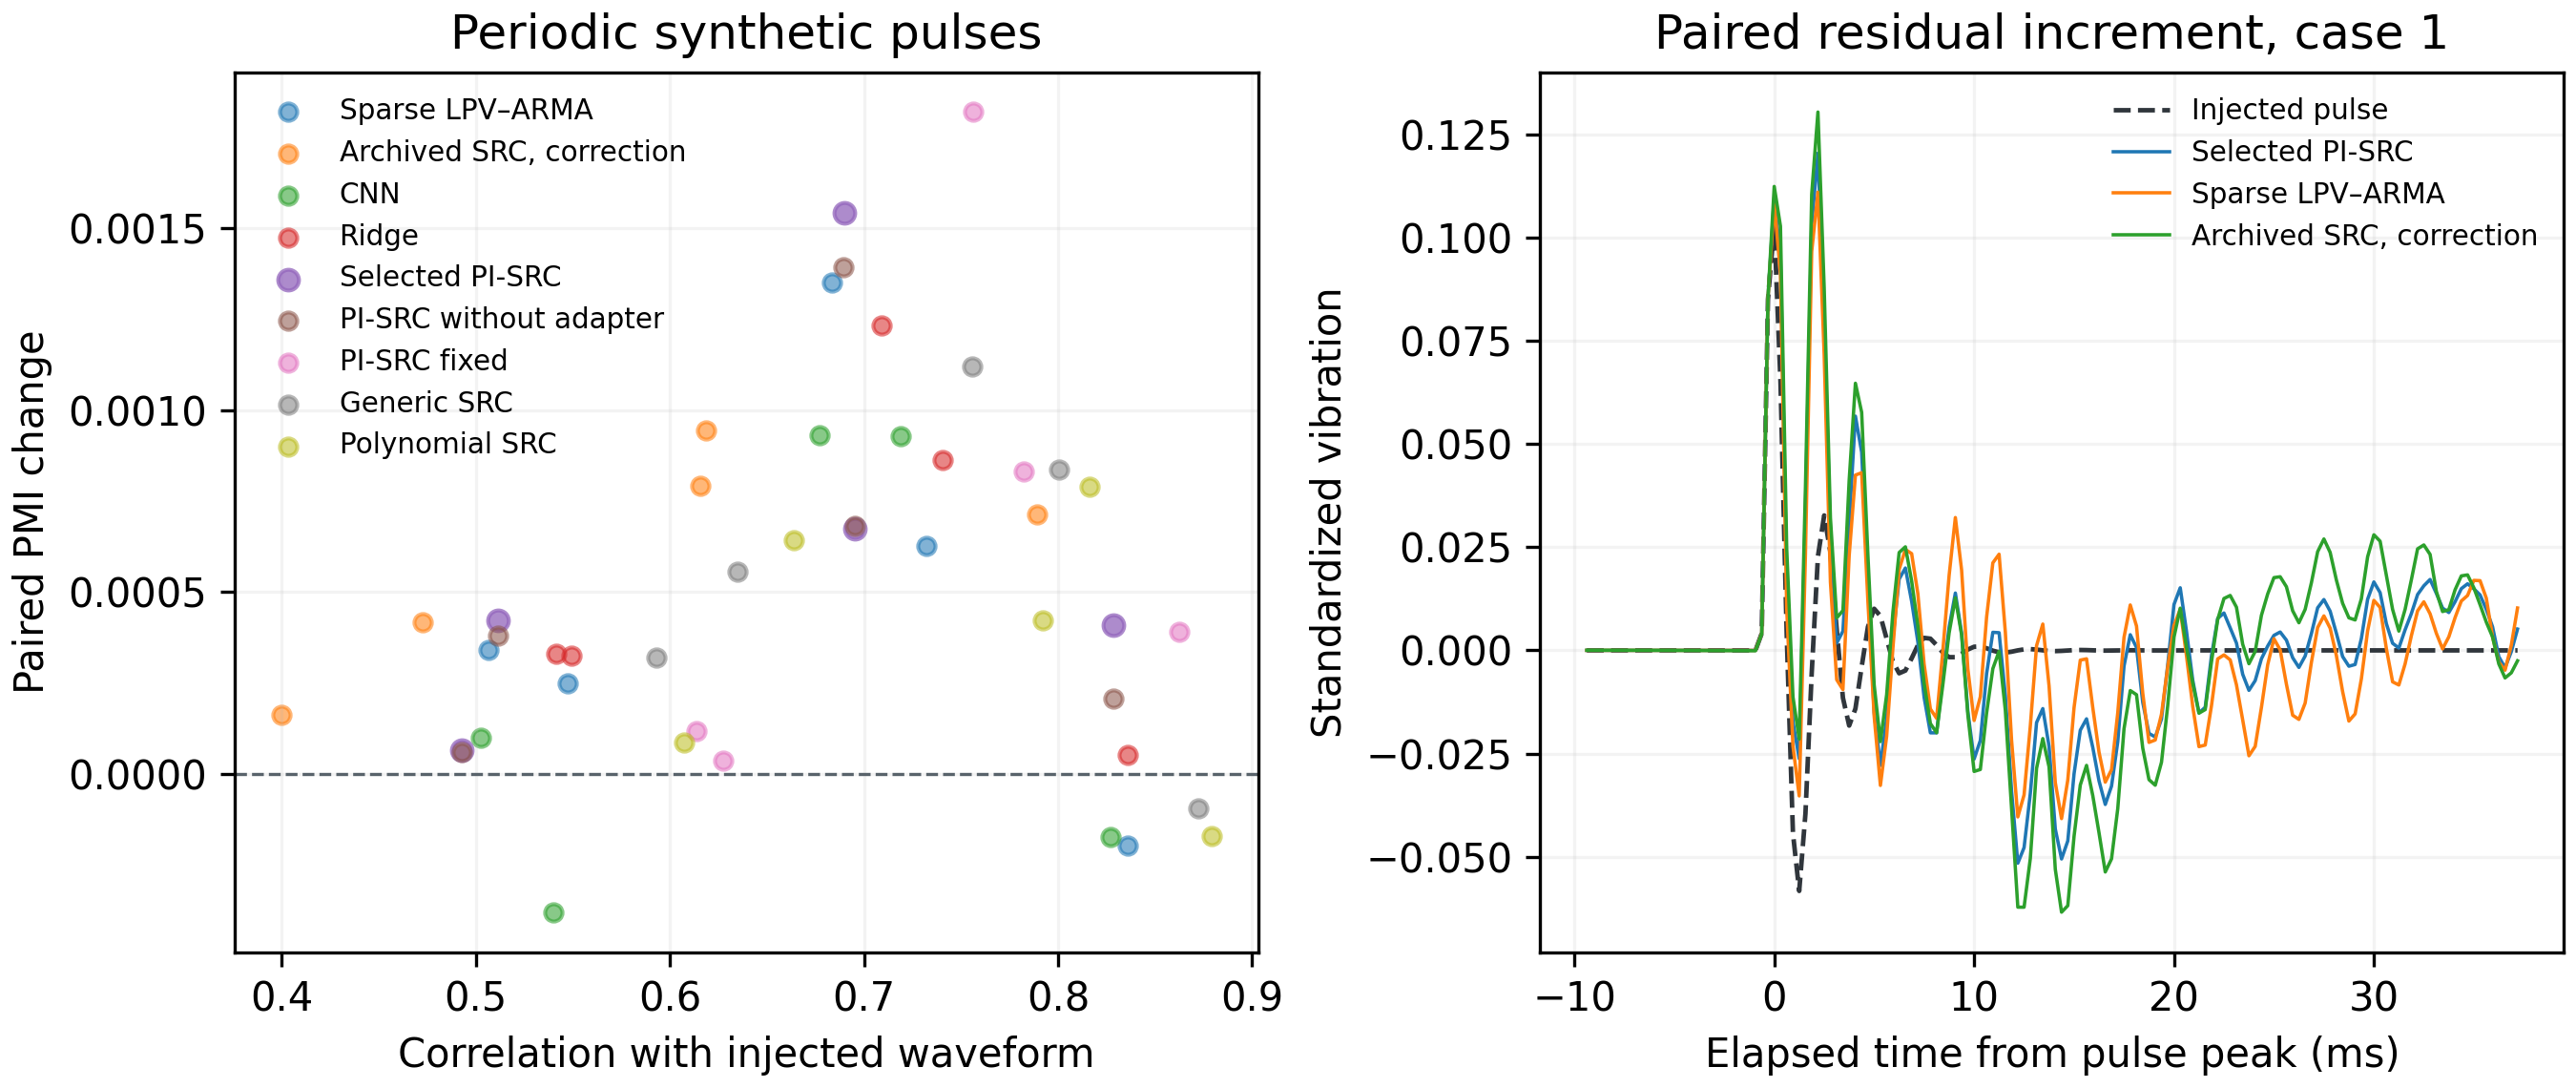

In [4]:
pulses = table("results/fault/pulse_summary.csv")
if pulses is not None:
    selected = pulses[pulses.model.isin(["primary_pi_src","pi_src_adapter_off","archived_src_corrected"])]
    display(selected)
show_fig("figures/fault/pulse_tradeoff.png")

### Interpretation and limits

Whole-record angle interpolation and the Hilbert transform are diagnostic
operations. Keep them separate from model inputs. A/B groups are provisional
indices and overlapping acquisitions are excluded. A diagnostic contrast with
conditional index groups cannot replace independently verified labels.
Missing MATLAB helpers or gold outputs restrict numerical parity claims.

Read the [Companion Guide](../docs/companion_guide.md) and the [Project README](../README.md).